# 作業二：ATP 網球紀錄分析

ATP（Association of Tennis Professionals，職業網球員協會）負責舉辦男子職業網球比賽。這份資料是 ATP 歷年的選手名單和比賽紀錄。

## 網球規則

網球是兩個人隔著一張網，用球拍把球打來打去，比誰先失誤。

- **場地**：長方形球場，中間有一張網，兩人各站一邊。場地四周畫了界線。
- **開始一分**：其中一人先發球，把球打到對面。發球要落在對面指定的區域（發球區）。
- **來回對打**：之後兩人輪流把球打過網。球在自己這邊最多只能彈地一次，要在彈第二次之前打回去。
- **輸掉一分**：球沒過網、球飛出對面的界線、或來不及在彈第二次前把球打回去，就輸這一分，對手得分。

職業選手一整年在世界各地參加比賽。

- **一站比賽**：每站比賽（tournament）大多是一對一淘汰制。贏的晉級下一輪，輸的就出局，最後剩下的人是冠軍。
- **排名**：贏越多場、比賽等級越高，拿到的積分越多。積分決定世界排名。
- **對應到資料**：比賽紀錄檔的一列就是一場比賽，記錄贏家（winner）、輸家（loser）和比分。

一場比賽的勝負不是只比一分，而是從小到大分成四層：分、局、盤、場。

- **分**：每一球打完，贏的人得一分。
- **局**：先拿 4 分的人贏這一局。分數的唸法是 0、15、30、40，不是 0、1、2、3。打到 40-40 時，要比對手多拿 2 分才算贏。
- **盤**：先贏 6 局的人贏這一盤，但要比對手多 2 局，所以會看到 7-5。打到 6-6 就改打搶七：先拿 7 分、而且多對手 2 分的人贏，這盤記成 7-6。
- **場**：一般比賽先贏 2 盤的人獲勝。四大滿貫要先贏 3 盤。欄位 `best_of` 就是 3 或 5。

發球的規則會影響後面的技術統計欄位。

- **輪流發球**：每一局由同一個人發球，下一局換人。發球的人通常比較有利。
- **Ace**：發出去的球，對手完全碰不到，直接得分。
- **雙誤（double fault）**：每一分有兩次發球機會，兩次都沒發進就直接輸這一分。
- **破發（break）**：沒發球的人贏了這一局。發球的人只差一分就要輸掉這局時，那一分叫破發點（break point）。

資料裡常用的代碼如下。

- **`tourney_level` 比賽等級**：G 是四大滿貫（Grand Slam），一年四場最大的比賽。M 是大師賽（Masters 1000），等級次之。A 是其他一般比賽。F 是年終總決賽（Tour Finals）。D 是台維斯盃（Davis Cup），國家隊對抗。O 是奧運（Olympics）。
- **`round` 第幾輪**：R128 表示這輪還剩 128 人（Round of 128），每輪淘汰一半。之後是 R64、R32、R16、QF 八強（Quarterfinal）、SF 四強（Semifinal）、F 決賽（Final）。RR 是分組循環賽（Round Robin），BR 是銅牌戰（Bronze）。
- **`surface` 場地**：Hard 硬地、Clay 紅土、Grass 草地。
- **`score` 比分**：`6-4 7-6(5)` 是兩盤，分別是 6-4 和 7-6。括號裡的 5 是搶七時輸的人拿到 5 分。結尾有 RET 表示有人打到一半退賽（Retired）。W/O 表示有人沒出賽，對手直接晉級（Walkover）。DEF 表示有人被判失格（Default）。
- **`winner_`、`loser_` 開頭**：贏家和輸家的資料。例如 `winner_age` 是贏家比賽當時的年齡。

## 1. 下載資料

先把 repo clone 下來。欄位的意思寫在 repo 裡的 `README.md` 和 `matches_data_dictionary.txt`。

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_URL: str = "https://github.com/Haz22537/JEFFSM_tennis_atp"
DATA_DIR: Path = Path("tennis_atp")

BLUE: str = "#2a78d6"
RED: str = "#e34948"
INK: str = "#0b0b0b"
INK_SECONDARY: str = "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK_SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 1,
    },
)

if not DATA_DIR.exists():
    subprocess.run(args=["git", "clone", "--depth", "1", REPO_URL, str(DATA_DIR)], check=True)

sorted(p.name for p in DATA_DIR.glob(pattern="*.txt")) + sorted(p.name for p in DATA_DIR.glob(pattern="*.md"))

['matches_data_dictionary.txt', 'README.md']

## 2. 選手名單

`atp_players.csv` 每一列是一位選手。

**有哪些欄位？** 共 8 欄。

- **`player_id`**：選手編號，比賽紀錄裡的 `winner_id`、`loser_id` 就是這個號碼。
- **`name_first`、`name_last`**：名、姓。
- **`hand`**：慣用手。R 右手、L 左手、A 左右手都用（Ambidextrous）、U 不知道（Unknown）。
- **`dob`**：生日（date of birth），格式是 YYYYMMDD 的數字，例如 19870522。
- **`ioc`**：國籍代碼，用國際奧會（IOC，International Olympic Committee）的三碼，例如 USA、TPE。
- **`height`**：身高，單位公分。
- **`wikidata_id`**：選手在維基資料庫（Wikidata）的編號。

In [2]:
players: pd.DataFrame = pd.read_csv(filepath_or_buffer=DATA_DIR / "atp_players.csv", low_memory=False)
players.columns.tolist()

['player_id',
 'name_first',
 'name_last',
 'hand',
 'dob',
 'ioc',
 'height',
 'wikidata_id']

**總共有多少選手？** 65,989 位。

In [3]:
len(players)

65989

**有多少選手生日不完整？** 18,504 位。

不完整分兩種。18,402 位完全沒有生日。另外 102 位只知道出生年份，月和日記成 00，例如 19650000。

In [4]:
dob: pd.Series = players["dob"]
dob_missing: int = dob.isna().sum()
dob_partial: int = (dob % 100 == 0).sum()  # day recorded as 00: only the year is known
pd.Series(data={"missing": dob_missing, "partial": dob_partial, "total": dob_missing + dob_partial})

missing    18402
partial      102
total      18504
dtype: int64

**哪些國家的選手最多？** 美國（USA）最多，有 13,228 位。接著是澳洲（AUS）、英國（GBR）、西班牙（ESP）、德國（GER），各約 3,000 位。

In [5]:
players["ioc"].value_counts().head(n=10)

ioc
USA    13228
AUS     3285
GBR     3281
ESP     3081
GER     2742
ITA     2726
FRA     2648
BRA     2104
ARG     1760
MEX     1342
Name: count, dtype: int64

**TPE 和 TWN 各有幾位？** TPE 有 201 位，TWN 只有 1 位。

TPE 是中華台北（Chinese Taipei），台灣在國際賽事使用的名稱。TWN 那一位是 Hou Chieh En，生日、身高等其他欄位都是空的。

In [6]:
players["ioc"].value_counts().reindex(index=["TPE", "TWN"])

ioc
TPE    201
TWN      1
Name: count, dtype: int64

In [7]:
players[players["ioc"] == "TWN"]

,player_id,name_first,name_last,hand,dob,ioc,height,wikidata_id
65397,213113,Chieh En,Hou,U,NaN,TWN,NaN,NaN


**TPE 選手有哪些姓？** 共 64 種姓。最多的是 Lin（林）22 位、Chen（陳）20 位、Huang（黃）10 位。

下面列出每個姓和人數。

In [8]:
players.loc[players["ioc"] == "TPE", "name_last"].value_counts().to_dict()

{'Lin': 22,
 'Chen': 20,
 'Huang': 10,
 'Wang': 9,
 'Chang': 9,
 'Lee': 8,
 'Hung': 6,
 'Yang': 6,
 'Hsu': 6,
 'Liu': 6,
 'Liao': 6,
 'Tsai': 6,
 'Wu': 5,
 'Tang': 4,
 'Hsieh': 4,
 'Yu': 4,
 'Lo': 4,
 'Lu': 3,
 'Liang': 3,
 'Cheng': 3,
 'Su': 2,
 'Ho': 2,
 'Chuang': 2,
 'Peng': 2,
 'Lai': 2,
 'Chan': 2,
 'Chien': 2,
 'Kao': 2,
 'Kuo': 2,
 'Hu': 2,
 'Shen': 2,
 'Mao': 2,
 'Shih': 2,
 'Shieh': 1,
 'Menn': 1,
 'Pan': 1,
 'Jung': 1,
 'Lien': 1,
 'Yi': 1,
 'Jao': 1,
 'Ko': 1,
 'Chiu': 1,
 'Tan': 1,
 'Wen': 1,
 'Meng': 1,
 'Ballout': 1,
 'Hsueh': 1,
 'Yeh': 1,
 'Li': 1,
 'Wei': 1,
 'Sung': 1,
 'Chiang': 1,
 'Chu': 1,
 'Yin': 1,
 'Tseng': 1,
 'He': 1,
 'Shie': 1,
 'Chung': 1,
 'Pai': 1,
 'Han': 1,
 'Fu': 1,
 'Wong': 1,
 'Ou': 1,
 'Hou': 1}

## 3. 比賽紀錄

比賽紀錄檔每一列是一場比賽。這裡讀 2021–2024 年的 4 個主巡迴賽檔，共 11,712 場。

中文題目的檔名寫法 `atp_matches*202[1234].csv` 會多讀到資格賽、挑戰賽和低級別比賽。這裡照英文題目的 `atp_matches_202[1-4].csv`，只讀主巡迴賽。

In [9]:
match_files: list[Path] = sorted(DATA_DIR.glob(pattern="atp_matches_202[1-4].csv"))
matches: pd.DataFrame = pd.concat(
    objs=[pd.read_csv(filepath_or_buffer=f) for f in match_files],
    ignore_index=True,
)
[f.name for f in match_files], len(matches)

(['atp_matches_2021.csv',
  'atp_matches_2022.csv',
  'atp_matches_2023.csv',
  'atp_matches_2024.csv'],
 11712)

**TPE 選手贏幾場、輸幾場？** 贏 17 場，輸 44 場。這 4 年沒有 TPE 選手互打的比賽。

In [10]:
pd.Series(
    data={
        "wins": (matches["winner_ioc"] == "TPE").sum(),
        "losses": (matches["loser_ioc"] == "TPE").sum(),
    },
)

wins      17
losses    44
dtype: int64

**有幾種比賽等級？** 6 種：A 一般比賽、M 大師賽、G 四大滿貫、D 台維斯盃、F 年終總決賽、O 奧運。

In [11]:
matches["tourney_level"].value_counts()

tourney_level
A    6302
M    2422
G    2032
D     817
F      75
O      64
Name: count, dtype: int64

**贏家比輸家高、一樣高、比較矮的各有幾場？** 贏家比較高 5,643 場，一樣高 1,325 場，比較矮 4,596 場。

有 148 場缺少其中一人的身高，先排除。

In [12]:
heights: pd.DataFrame = matches.dropna(subset=["winner_ht", "loser_ht"]).copy()
heights["winner_is"] = np.sign(heights["winner_ht"] - heights["loser_ht"]).map(
    arg={1: "taller", 0: "same", -1: "shorter"},
)
heights["winner_is"].value_counts()

winner_is
taller     5643
shorter    4596
same       1325
Name: count, dtype: int64

**不同比賽等級裡，身高和輸贏有什麼關係？** 每種等級都是高的人贏比較多，奧運除外。

`taller_win_rate` 只看兩人身高不同的比賽，算高的人贏的比例。整體是 55%，四大滿貫最高，有 57.5%。奧運只有 64 場，高的人只贏 48%，場數太少，不能下結論。

In [13]:
by_level: pd.DataFrame = pd.crosstab(index=heights["tourney_level"], columns=heights["winner_is"])
by_level["taller_win_rate"] = (by_level["taller"] / (by_level["taller"] + by_level["shorter"])).round(decimals=3)
by_level

winner_is,same,shorter,taller,taller_win_rate
tourney_level,,,,
A,727,2545,3023,0.543
D,90,284,303,0.516
F,10,32,33,0.508
G,225,767,1039,0.575
M,269,937,1216,0.565
O,4,31,29,0.483


### 年齡

先把年齡四捨五入成整數。資料裡的年齡是比賽當時的年齡。

In [14]:
matches["winner_age"] = matches["winner_age"].round().astype(dtype="Int64")
matches["loser_age"] = matches["loser_age"].round().astype(dtype="Int64")

**贏家的年齡分布？** 26 歲的贏家最多，有 1,271 場。其次是 24 歲和 25 歲。

In [15]:
matches["winner_age"].value_counts()

winner_age
26    1271
24    1180
25    1125
27    1071
28     846
22     812
23     792
30     545
29     541
21     525
20     425
31     383
34     367
32     364
33     321
35     270
36     260
19     240
37     136
38      98
18      82
40      24
39      14
42       7
17       6
44       2
41       1
43       1
45       1
Name: count, dtype: Int64

**各年齡的勝率？** 21 歲最高，勝率 55.6%。

做法是把每場比賽拆成兩列：贏家一列記 `win` = 1，輸家一列記 `win` = 0。這樣選手每打一場就有一列，`win` 的平均就是勝率。

19–27 歲的勝率都在 50% 以上，28 歲之後掉到 50% 以下。34–36 歲又回到 50% 以上，可能是因為打到這個年紀還沒退休的多半是頂尖選手。15–17 歲和 39 歲以上的場數很少，勝率參考就好。

In [16]:
winner_rows: pd.DataFrame = matches.rename(
    columns={"winner_name": "name", "winner_age": "age", "loser_age": "opp_age"},
)[["name", "age", "opp_age"]].assign(win=1)
loser_rows: pd.DataFrame = matches.rename(
    columns={"loser_name": "name", "loser_age": "age", "winner_age": "opp_age"},
)[["name", "age", "opp_age"]].assign(win=0)
games: pd.DataFrame = pd.concat(objs=[winner_rows, loser_rows], ignore_index=True)

games.groupby(by="age")["win"].agg(matches="count", win_rate="mean").round(decimals=3)

,matches,win_rate
age,,
15,1,0.000
16,6,0.000
17,27,0.222
18,179,0.458
19,454,0.529
20,803,0.529
21,944,0.556
22,1534,0.529
23,1499,0.528


**贏最多場的前十名？** Jannik Sinner 最多，4 年贏 237 場。

In [17]:
matches["winner_name"].value_counts().head(n=10)

winner_name
Jannik Sinner         237
Daniil Medvedev       221
Alexander Zverev      213
Stefanos Tsitsipas    212
Carlos Alcaraz        208
Andrey Rublev         205
Casper Ruud           197
Novak Djokovic        193
Taylor Fritz          187
Alex De Minaur        168
Name: count, dtype: int64

**勝率最高的前十名？** Novak Djokovic 最高，勝率 86.2%。

只打幾場的人勝率會失真，例如打 1 場贏 1 場就是 100%。所以只算 4 年內打滿 50 場的選手。

In [18]:
MIN_MATCHES: int = 50

player_stats: pd.DataFrame = games.groupby(by="name")["win"].agg(matches="count", win_rate="mean")
(
    player_stats[player_stats["matches"] >= MIN_MATCHES]
    .sort_values(by="win_rate", ascending=False)
    .head(n=10)
    .round(decimals=3)
)

,matches,win_rate
name,,
Novak Djokovic,224,0.862
Carlos Alcaraz,263,0.791
Jannik Sinner,301,0.787
Daniil Medvedev,292,0.757
Rafael Nadal,102,0.755
Alexander Zverev,287,0.742
Matteo Berrettini,167,0.707
Stefanos Tsitsipas,301,0.704
Nick Kyrgios,68,0.691


**不同年齡互打的場數（19–28 歲）**

列是贏家年齡，欄是輸家年齡，格子裡是場數。例如第 22 列、第 25 欄，就是 22 歲贏 25 歲的場數。只算兩人都在 19–28 歲的比賽。

In [19]:
in_range: pd.Series = matches["winner_age"].between(left=19, right=28) & matches["loser_age"].between(left=19, right=28)
young: pd.DataFrame = matches[in_range]
pd.crosstab(index=young["winner_age"], columns=young["loser_age"])

loser_age,19,20,21,22,23,24,25,26,27,28
winner_age,,,,,,,,,,
19,3,11,12,15,16,22,24,23,16,19
20,11,19,16,33,30,29,33,47,54,25
21,12,14,22,32,30,50,40,71,35,49
22,12,22,29,44,46,65,62,81,78,77
23,6,28,32,34,55,64,66,71,85,69
24,18,37,43,82,58,117,104,115,95,84
25,17,29,46,73,65,115,91,107,94,100
26,31,41,47,73,79,135,102,115,107,115
27,27,30,38,70,78,91,95,117,92,96


**不同年齡互打的勝率**

列是選手年齡，欄是對手年齡，格子裡是勝率。例如第 22 列、第 25 欄，就是 22 歲打 25 歲的勝率。

表格算了所有年齡，但很多格只有幾場比賽，這裡只顯示 19–28 歲。對角線一定是 50%，因為同年齡互打時，贏家和輸家算在同一格。

In [20]:
win_rate: pd.DataFrame = games.pivot_table(
    index="age",
    columns="opp_age",
    values="win",
    aggfunc="mean",
)
win_rate.loc[19:28, 19:28].round(decimals=2)

opp_age,19,20,21,22,23,24,25,26,27,28
age,,,,,,,,,,
19,0.50,0.50,0.50,0.56,0.73,0.55,0.59,0.43,0.37,0.49
20,0.50,0.50,0.53,0.60,0.52,0.44,0.53,0.53,0.64,0.44
21,0.50,0.47,0.50,0.52,0.48,0.54,0.47,0.60,0.48,0.65
22,0.44,0.40,0.48,0.50,0.57,0.44,0.46,0.53,0.53,0.57
23,0.27,0.48,0.52,0.42,0.50,0.52,0.50,0.47,0.52,0.58
24,0.45,0.56,0.46,0.56,0.48,0.50,0.47,0.46,0.51,0.58
25,0.41,0.47,0.53,0.54,0.50,0.53,0.50,0.51,0.50,0.57
26,0.57,0.47,0.40,0.47,0.53,0.54,0.49,0.50,0.48,0.55
27,0.63,0.36,0.52,0.47,0.48,0.49,0.50,0.52,0.50,0.56


**哪些年齡對每個年齡的勝率都在 49% 以上（19–28 歲）？** 沒有。

每個年齡都至少對一個年齡的勝率低於 49%。最接近的是 21 歲，最差是對 25 歲，勝率 46.5%。

In [21]:
rate_19_28: pd.DataFrame = win_rate.loc[19:28, 19:28]
(rate_19_28 > 0.49).all(axis="columns")

age
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
dtype: bool

In [22]:
pd.DataFrame(
    data={
        "min_win_rate": rate_19_28.min(axis="columns").round(decimals=3),
        "vs_age": rate_19_28.idxmin(axis="columns"),
    },
)

,min_win_rate,vs_age
age,,
19,0.372,27
20,0.439,28
21,0.465,25
22,0.400,20
23,0.273,19
24,0.450,19
25,0.415,19
26,0.398,21
27,0.357,20


## 4. 自訂問題

**問題一：選手的身高是不是常態分佈？** 大致是。

常態分佈就是鐘形分佈：大部分人集中在平均附近，越往兩邊越少，而且左右對稱。

對象是 2021–2024 年有出賽的選手。比賽紀錄裡同一個人會出現很多次，所以每位選手只算一次。

In [23]:
both_sides: list[pd.DataFrame] = [
    matches[[f"{side}_id", f"{side}_name", f"{side}_ht"]].set_axis(labels=["id", "name", "height"], axis="columns")
    for side in ["winner", "loser"]
]
active_players: pd.DataFrame = (
    pd.concat(objs=both_sides, ignore_index=True)
    .dropna(subset=["height"])
    .drop_duplicates(subset="id")
)
active_players.nsmallest(n=3, columns="height")

,id,name,height
5605,134087,Johannes Ingildsen,15.0
8572,209907,Viacheslav Bielinskyi,71.0
2678,202122,Yuta Shimizu,163.0


先檢查資料。有兩筆身高明顯是錯的：15 cm 和 71 cm。正常的最矮是 163 cm，所以排除 150 cm 以下的資料，剩 642 人。

接著看三個數字：
- **平均和標準差**：平均 185.7 cm。標準差 6.5 cm，意思是大家和平均大約差 6.5 cm。
- **偏態（skew）**：左右對不對稱。常態分佈是 0，正的代表右邊尾巴比較長。這裡是 0.21，接近對稱。
- **峰態（kurt）**：兩邊尾巴比常態分佈厚還是薄。常態分佈是 0，這裡是 0.5，尾巴稍厚一點。

In [24]:
heights_clean: pd.Series = active_players.loc[active_players["height"] >= 150, "height"]
pd.Series(
    data={
        "players": len(heights_clean),
        "mean": heights_clean.mean(),
        "std": heights_clean.std(),
        "skew": heights_clean.skew(),
        "kurt": heights_clean.kurt(),
    },
).round(decimals=2)

players    642.00
mean       185.74
std          6.51
skew         0.21
kurt         0.50
dtype: float64

畫出身高的直方圖：每 5 cm 一組，長條高度是人數。人數集中在 180–195 cm，往兩邊遞減，是鐘形。

灰線是理論上的常態分佈曲線 $f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/(2\sigma^2)}$。$\mu$ 是平均，決定曲線最高點的位置。$\sigma$ 是標準差，越大曲線越矮越寬。這裡代入 $\mu$ = 185.7、$\sigma$ = 6.5，再乘上人數和組寬換算成人數。長條和曲線很貼近。

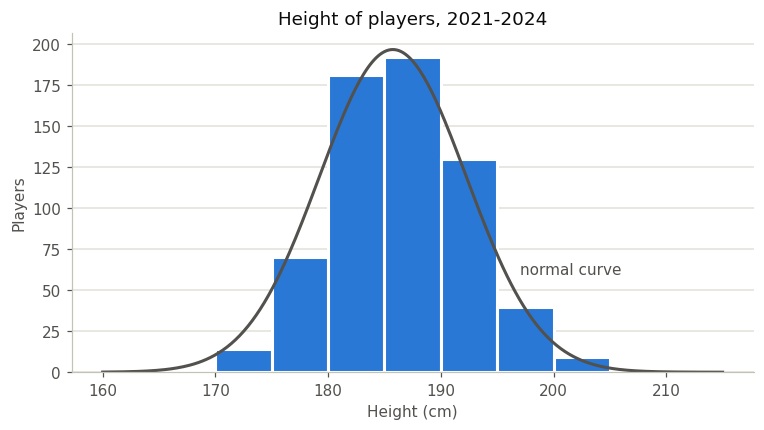

In [25]:
BIN_WIDTH: int = 5
mu: float = heights_clean.mean()
sigma: float = heights_clean.std()
x: np.ndarray = np.linspace(start=160, stop=215, num=300)
normal_count: np.ndarray = len(heights_clean) * BIN_WIDTH * np.exp(-((x - mu) ** 2) / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(8, 4))
heights_clean.plot.hist(ax=ax, bins=range(160, 220, BIN_WIDTH), color=BLUE, edgecolor="white", linewidth=2)
ax.plot(x, normal_count, color=INK_SECONDARY, linewidth=2)
ax.annotate(text="normal curve", xy=(197, 60), color=INK_SECONDARY)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.set(title="Height of players, 2021-2024", xlabel="Height (cm)", ylabel="Players")
plt.show()

再畫 boxplot（盒鬚圖）。它用五個位置描述資料：

- **中位數**：身高從矮排到高，正中間那個人的身高，盒子裡的黑線。這裡是 185 cm。
- **盒子**：左邊界是排在 25% 的身高（第一四分位數 Q1），右邊界是排在 75% 的身高（第三四分位數 Q3）。中間一半的人都在盒子裡，這裡是 183–191 cm。
- **鬚**：從盒子往兩邊延伸，最遠到離盒子 1.5 倍盒子寬度內的最後一個人。盒子寬 8 cm，所以鬚最遠到 171 cm 和 203 cm。
- **離群值**：超出鬚的點。

上排是原始資料，15 cm 和 71 cm 兩筆離其他人非常遠，一看就是錯誤。下排是排除錯誤後的資料。

常態分佈的 boxplot 應該左右對稱，離群值約佔 0.7%。這裡盒子右半邊比較長，代表 185 cm 以上的人分布得比較散，和偏態 0.21 一致。離群值有 10 人（1.6%），同身高的點疊在一起，所以圖上只看到 5 個點。這比常態分佈多一些，和峰態 0.5（尾巴稍厚）一致。

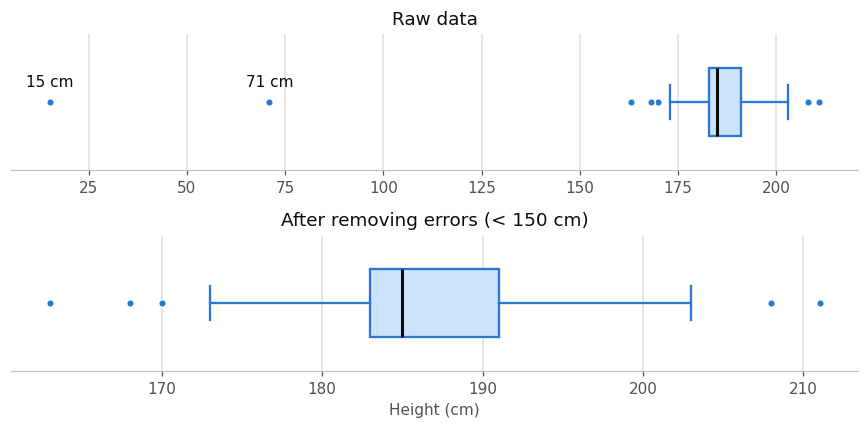

In [26]:
fig, (ax_raw, ax_clean) = plt.subplots(nrows=2, figsize=(8, 4))
box_style: dict = {
    "orientation": "horizontal",
    "widths": 0.5,
    "patch_artist": True,
    "boxprops": {"facecolor": "#cde2fb", "edgecolor": BLUE, "linewidth": 1.5},
    "whiskerprops": {"color": BLUE, "linewidth": 1.5},
    "capprops": {"color": BLUE, "linewidth": 1.5},
    "medianprops": {"color": INK, "linewidth": 2},
    "flierprops": {"marker": "o", "markersize": 5, "markerfacecolor": BLUE, "markeredgecolor": "white"},
}
ax_raw.boxplot(active_players["height"], **box_style)
for h in active_players["height"].nsmallest(n=2):
    ax_raw.annotate(text=f"{h:.0f} cm", xy=(h, 1), xytext=(0, 10), textcoords="offset points", ha="center", color=INK)
ax_raw.set(title="Raw data", yticks=[])

ax_clean.boxplot(heights_clean, **box_style)
ax_clean.set(title="After removing errors (< 150 cm)", xlabel="Height (cm)", yticks=[])

for ax in (ax_raw, ax_clean):
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

最後用 68–95–99.7 法則檢查。常態分佈裡，離平均 1 個標準差內約有 68.3% 的人，2 個標準差內約 95.4%，3 個標準差內約 99.7%。

先算每個人離平均幾個標準差：(身高 − 平均) ÷ 標準差。例如 192.2 cm 的人是 (192.2 − 185.7) ÷ 6.5 = 1 個標準差。再看落在 1、2、3 個標準差內的人各佔多少。

實際比例是 69.9%、97.0%、99.4%，和常態分佈很接近，所以身高大致符合常態分佈。

In [27]:
z: pd.Series = (heights_clean - heights_clean.mean()) / heights_clean.std()
pd.DataFrame(
    data={
        "actual": [(z.abs() <= k).mean() for k in (1, 2, 3)],
        "normal": [0.683, 0.954, 0.997],
    },
    index=["within 1 std", "within 2 std", "within 3 std"],
).round(decimals=3)

,actual,normal
within 1 std,0.699,0.683
within 2 std,0.970,0.954
within 3 std,0.994,0.997


**問題二：哪些因素和贏球最有關？** 發球表現最有關，特別是一發得分率、二發得分率和被破發的機會。比賽前就知道的條件裡，排名最有關，身高和年齡幾乎沒關係。

這裡用相關係數衡量兩個數字是不是一起變化。
- **範圍**：介於 −1 到 1。
- **正值**：一個變大，另一個也跟著變大，1 代表完全同步。
- **負值**：一個變大，另一個反而變小。
- **0**：兩者沒有直線關係。
- **不代表因果**：只說明兩者一起變化，不能說誰造成誰。

公式是 $r=\frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum (x_i-\bar{x})^2}\sqrt{\sum (y_i-\bar{y})^2}}$，$\bar{x}$、$\bar{y}$ 是平均。分子逐筆檢查兩個數字是否同時高於或同時低於各自的平均：同時高或同時低就加，一高一低就減。分母把結果縮放到 −1 到 1 之間。

資料的整理方式和第 3 部分算勝率一樣：每場拆成兩列，贏家記 `win` = 1，輸家記 `win` = 0。每列的欄位如下。
- **`height`、`age`**：身高、年齡。
- **`log_rank`**：排名取 $\log_{10}$，數字越小越強。排名 1、10、100、1000 取完變成 0、1、2、3，第 1 名和第 10 名的差距，就和第 100 名與第 1000 名一樣大。不取的話，後段選手的大數字會蓋過前段的差異。
- **`ace_rate`**：Ace 佔所有發球分的比例。
- **`df_rate`**：雙誤佔所有發球分的比例。
- **`first_in`**：一發進球率。
- **`first_won`**：一發進球後，拿下這一分的比例。
- **`second_won`**：打二發時，拿下這一分的比例。
- **`bp_faced`**：平均每個發球局面對幾個破發點。

發球數據用比例而不用次數，因為比賽打得越久，次數自然越多。排除沒有技術統計的比賽，以及問題一找到的兩筆身高錯誤後，剩 22,267 列。

In [28]:
feature_frames: list[pd.DataFrame] = []
for side, prefix, win in [("winner", "w", 1), ("loser", "l", 0)]:
    serve_points: pd.Series = matches[f"{prefix}_svpt"]
    first_in: pd.Series = matches[f"{prefix}_1stIn"]
    feature_frames.append(
        pd.DataFrame(
            data={
                "win": win,
                "height": matches[f"{side}_ht"],
                "age": matches[f"{side}_age"].astype(dtype=float),
                "log_rank": np.log10(matches[f"{side}_rank"]),
                "ace_rate": matches[f"{prefix}_ace"] / serve_points,
                "df_rate": matches[f"{prefix}_df"] / serve_points,
                "first_in": first_in / serve_points,
                "first_won": matches[f"{prefix}_1stWon"] / first_in,
                "second_won": matches[f"{prefix}_2ndWon"] / (serve_points - first_in),
                "bp_faced": matches[f"{prefix}_bpFaced"] / matches[f"{prefix}_SvGms"],
            },
        ),
    )
features: pd.DataFrame = (
    pd.concat(objs=feature_frames, ignore_index=True)
    .replace(to_replace=[np.inf, -np.inf], value=np.nan)
    .dropna()
)
features = features[features["height"] >= 150]  # drop the two height errors found in question 1
len(features)

22267

先看每個因素和 `win` 的相關係數，列出正相關和負相關最強的前三項。

In [29]:
TOP_N: int = 3

corr: pd.DataFrame = features.corr()
win_corr: pd.Series = corr["win"].drop(labels="win")
print(f"Top {TOP_N} positive with win:")
print(win_corr.nlargest(n=TOP_N).round(decimals=2).to_string())
print(f"\nTop {TOP_N} negative with win:")
print(win_corr.nsmallest(n=TOP_N).round(decimals=2).to_string())

Top 3 positive with win:
first_won     0.51
second_won    0.46
ace_rate      0.24

Top 3 negative with win:
bp_faced   -0.47
log_rank   -0.21
df_rate    -0.15


再看所有因素兩兩之間的相關係數，也就是相關矩陣。藍色是正相關，紅色是負相關，顏色越深關係越強。對角線是自己和自己，一定是 1。

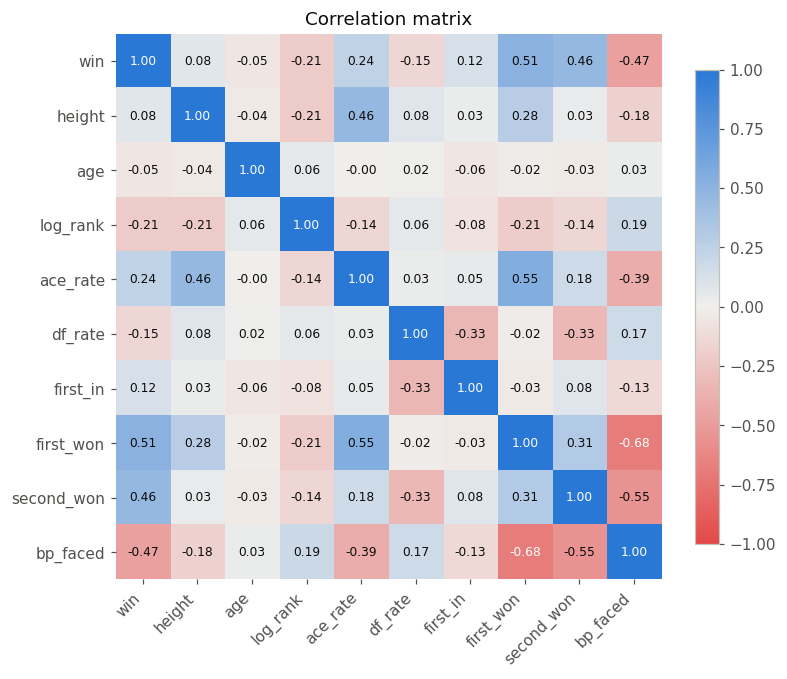

In [30]:
from matplotlib.colors import LinearSegmentedColormap

diverging = LinearSegmentedColormap.from_list(name="red_gray_blue", colors=[RED, "#f0efec", BLUE])

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr.to_numpy(), cmap=diverging, vmin=-1, vmax=1)
for r in range(len(corr)):
    for c in range(len(corr)):
        value: float = corr.iloc[r, c]
        ax.text(
            c,
            r,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) > 0.6 else INK,
        )
ax.set_xticks(ticks=range(len(corr)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(ticks=range(len(corr)), labels=corr.index)
ax.spines[:].set_visible(False)
ax.set_title(label="Correlation matrix")
fig.colorbar(mappable=image, ax=ax, shrink=0.8)
plt.show()

再從矩陣裡找出因素兩兩之間，正相關和負相關最強的前三組。`win` 已經在上面看過，這裡排除。每組只算一次，因為 A 對 B 和 B 對 A 的相關係數一樣。

In [31]:
factor_corr: pd.DataFrame = corr.drop(index="win", columns="win")
upper: np.ndarray = np.triu(m=np.ones(shape=factor_corr.shape, dtype=bool), k=1)  # keep each pair once
pairs: pd.Series = factor_corr.where(cond=upper).stack(future_stack=True).dropna()
pairs.index = [f"{a} - {b}" for a, b in pairs.index]
print(f"Top {TOP_N} positive pairs:")
print(pairs.nlargest(n=TOP_N).round(decimals=2).to_string())
print(f"\nTop {TOP_N} negative pairs:")
print(pairs.nsmallest(n=TOP_N).round(decimals=2).to_string())

Top 3 positive pairs:
ace_rate - first_won      0.55
height - ace_rate         0.46
first_won - second_won    0.31

Top 3 negative pairs:
first_won - bp_faced    -0.68
second_won - bp_faced   -0.55
ace_rate - bp_faced     -0.39


結論分兩類看。

- **比賽中的表現**：一發得分率（0.51）、二發得分率（0.46）、每個發球局面對的破發點（−0.47）和贏球最有關。這幾項本身就是比賽結果的一部分，發球局守得住自然比較會贏，所以相關高是理所當然。
- **比賽前就知道的條件**：排名最有關（−0.21），排名越前面越容易贏。身高（0.08）和年齡（−0.05）幾乎沒關係。

矩陣裡還有兩個發現。
- **高的人 Ace 比較多**：身高和 Ace 比例的相關是 0.46。這可以解釋第 3 部分「高的人贏得比較多」，但身高和贏球本身的相關只有 0.08，影響很小。
- **一發得分率高，被破發的機會就少**：兩者的相關是 −0.68，是矩陣裡最強的關係。

**問題三：左手選手有優勢嗎？** 沒有。左手選手的勝率 47.7%，比右手的 50.5% 低。左手對右手的比賽有 2,705 場，左手只贏 47.4%。

網球圈常說左手有優勢：大部分對手是右手，平常很少練到左手選手的球路，所以不習慣。這裡用 2021–2024 的比賽紀錄檢查。

`hand` 欄位是慣用手：R 右手、L 左手、U 不知道。U 只有 75 列，不討論。

做法和第 3 部分算勝率一樣，每場拆成兩列，再依慣用手算勝率。

In [32]:
hand_rows: pd.DataFrame = pd.concat(
    objs=[
        matches.rename(columns={"winner_name": "name", "winner_hand": "hand"})[["name", "hand"]].assign(win=1),
        matches.rename(columns={"loser_name": "name", "loser_hand": "hand"})[["name", "hand"]].assign(win=0),
    ],
    ignore_index=True,
)
hand_rows.groupby(by="hand")["win"].agg(matches="count", win_rate="mean").round(decimals=3)

,matches,win_rate
hand,,
L,3125,0.477
R,20224,0.504
U,75,0.227


再只看左手對右手的比賽，直接比誰贏得多。

In [33]:
left_vs_right: pd.DataFrame = matches[
    (matches["winner_hand"] != matches["loser_hand"]) & matches["winner_hand"].isin(values=["L", "R"]) & matches["loser_hand"].isin(values=["L", "R"])
]
pd.Series(
    data={
        "matches": len(left_vs_right),
        "left_win_rate": (left_vs_right["winner_hand"] == "L").mean().round(decimals=3),
    },
)

matches          2705.000
left_win_rate       0.474
dtype: float64

勝率沒有比較高，但左手選手並不少。2021–2024 出賽的選手裡，左手佔 12.3%，比一般人口約一成多一點。也就是左手選手打進職業圈的比例不低，只是上場後沒有贏得比較多。

In [34]:
active_hands: pd.DataFrame = pd.concat(
    objs=[
        matches[["winner_id", "winner_hand"]].set_axis(labels=["id", "hand"], axis="columns"),
        matches[["loser_id", "loser_hand"]].set_axis(labels=["id", "hand"], axis="columns"),
    ],
    ignore_index=True,
).drop_duplicates(subset="id")
active_hands["hand"].value_counts(normalize=True).round(decimals=3)

hand
R    0.812
L    0.123
U    0.064
Name: proportion, dtype: float64

左手選手裡勝率最高的是 Rafael Nadal，75.5%。門檻和第 3 部分一樣，只算 4 年內打滿 50 場的選手。

In [35]:
left_stats: pd.DataFrame = hand_rows[hand_rows["hand"] == "L"].groupby(by="name")["win"].agg(matches="count", win_rate="mean")
(
    left_stats[left_stats["matches"] >= MIN_MATCHES]
    .sort_values(by="win_rate", ascending=False)
    .head(n=5)
    .round(decimals=3)
)

,matches,win_rate
name,,
Rafael Nadal,102,0.755
Cameron Norrie,254,0.622
Jack Draper,130,0.608
Ben Shelton,123,0.569
Denis Shapovalov,189,0.550


**問題四：場地會改變比賽嗎？** 會。草地 Ace 率最高，9.6%，紅土最低，5.1%。紅土每盤打最久，中位數約 46 分鐘，草地最短，42 分鐘。各場地最強的人也不同：硬地和草地是 Novak Djokovic，紅土前三名幾乎打平，Matteo Berrettini、Carlos Alcaraz、Novak Djokovic 都約 82%。

ATP 比賽用三種場地（`surface`）。

- **硬地（Hard）**：水泥加塗層，球速中等，場數最多。
- **紅土（Clay）**：碎磚粉鋪成，球速慢、彈得高，來回多。
- **草地（Grass）**：真草，球速快、彈得低，發球好的人占便宜。

用三個數字比較場地。

- **Ace 率**：Ace 是發球直接得分，對手連碰都沒碰到。這裡把一場比賽兩人的 Ace 加起來，除以兩人的總發球分數。
- **每盤分鐘數**：比賽分鐘數除以盤數。用每盤不用每場，因為大滿貫是五盤三勝，其他比賽多是三盤兩勝，直接比每場時間不公平。盤數從 `score` 數有幾個「數字-數字」。
- **高的人勝率**：第 3 部分算過整體是 55%，這裡分場地看。

有 53 場沒記錄場地、77 場是對手棄賽（`score` 寫 W/O，walkover，沒有比分和時間），先排除。沒有時間或技術統計的比賽在各自的平均裡會自動略過。

In [36]:
played: pd.DataFrame = matches[matches["surface"].notna() & (matches["score"] != "W/O")].copy()
played["ace_rate"] = (played["w_ace"] + played["l_ace"]) / (played["w_svpt"] + played["l_svpt"])
played["sets"] = played["score"].str.count(pat=r"\d+-\d+")
played["minutes_per_set"] = played["minutes"] / played["sets"]
played["taller_won"] = np.sign(played["winner_ht"] - played["loser_ht"]).replace(to_replace={0: np.nan, -1: 0})
played.groupby(by="surface").agg(
    matches=("surface", "size"),
    ace_rate=("ace_rate", "mean"),
    minutes_per_set=("minutes_per_set", "median"),
    taller_win_rate=("taller_won", "mean"),
).round(decimals=3)

,matches,ace_rate,minutes_per_set,taller_win_rate
surface,,,,
Clay,3507,0.051,45.667,0.531
Grass,1278,0.096,42.000,0.565
Hard,6797,0.086,44.000,0.560


草地球速快，Ace 率將近紅土的兩倍。紅土球速慢，一分來回久，所以每盤最久。高的人在草地和硬地贏 56%，在紅土只贏 53%，因為紅土把發球優勢削掉一部分。

再看各場地勝率最高的三位選手。只算在該場地打滿 20 場的人，門檻比第 3 部分低，因為草地一年只有幾站。

In [37]:
surface_rows: pd.DataFrame = pd.concat(
    objs=[
        played.rename(columns={"winner_name": "name"})[["name", "surface"]].assign(win=1),
        played.rename(columns={"loser_name": "name"})[["name", "surface"]].assign(win=0),
    ],
    ignore_index=True,
)
surface_stats: pd.DataFrame = surface_rows.groupby(by=["surface", "name"])["win"].agg(matches="count", win_rate="mean")
(
    surface_stats[surface_stats["matches"] >= 20]
    .sort_values(by=["surface", "win_rate"], ascending=[True, False])
    .groupby(level="surface")
    .head(n=3)
    .round(decimals=3)
)

matches  win_rate
surface name                                
Clay    Matteo Berrettini       41     0.829
        Carlos Alcaraz          97     0.825
        Novak Djokovic          73     0.822
Grass   Novak Djokovic          27     0.926
        Carlos Alcaraz          27     0.889
        Matteo Berrettini       35     0.829
Hard    Novak Djokovic         120     0.875
        Jannik Sinner          204     0.824
        Daniil Medvedev        211     0.773

Novak Djokovic 硬地和草地都是第一，草地 27 場贏 25 場，而且三種場地都進前三，是唯一全能的。紅土前三名勝率只差 0.7%，Matteo Berrettini 場數最少，41 場。Carlos Alcaraz 紅土和草地進前三，Jannik Sinner 和 Daniil Medvedev 只在硬地，是典型的硬地選手。

**問題五：排名高的人多常贏？哪種比賽最常出冷門？** 排名高的人贏 63.9%。差距越大越穩：兩人排名差不到 1.25 倍時，排名高的只贏 52%，差 10 倍以上時贏 83%。年終總決賽最常出冷門，排名高的只贏 55%；奧運和大滿貫最少。

冷門（upset）是排名低的人打贏排名高的人。排名用比賽當時的 `winner_rank`、`loser_rank`，數字越小越強。有 144 場缺排名，排除。

差距用倍數算，不用名次差。第 1 名對第 2 名，和第 100 名對第 101 名，名次都只差 1，但前者是兩個頂尖選手，後者實力差不多。改成倍數後，第 1 名對第 10 名和第 100 名對第 1000 名都是差 10 倍，這樣比才公平。這和問題二取 $\log_{10}$ 是同一個想法。

In [38]:
ranked: pd.DataFrame = matches.dropna(subset=["winner_rank", "loser_rank"]).copy()
ranked["favorite_won"] = ranked["winner_rank"] < ranked["loser_rank"]
ranked["rank_ratio"] = ranked[["winner_rank", "loser_rank"]].max(axis="columns") / ranked[["winner_rank", "loser_rank"]].min(axis="columns")
pd.Series(data={"matches": len(ranked), "favorite_win_rate": ranked["favorite_won"].mean().round(decimals=3)})

matches              11568.000
favorite_win_rate        0.639
dtype: float64

把倍數分成幾組，看排名高的人的勝率怎麼變。例如 [1, 1.25) 是兩人排名差不到 1.25 倍，第 40 名對第 49 名就在這組。

In [39]:
RATIO_EDGES: list[float] = [1, 1.25, 1.5, 2, 3, 5, 10, np.inf]

ratio_group: pd.Series = pd.cut(x=ranked["rank_ratio"], bins=RATIO_EDGES, right=False)
by_ratio: pd.DataFrame = ranked.groupby(by=ratio_group, observed=True)["favorite_won"].agg(matches="count", favorite_win_rate="mean")
by_ratio.round(decimals=3)

,matches,favorite_win_rate
rank_ratio,,
"[1.0, 1.25)",1429,0.521
"[1.25, 1.5)",1253,0.547
"[1.5, 2.0)",1825,0.562
"[2.0, 3.0)",2048,0.590
"[3.0, 5.0)",1986,0.675
"[5.0, 10.0)",1652,0.752
"[10.0, inf)",1375,0.833


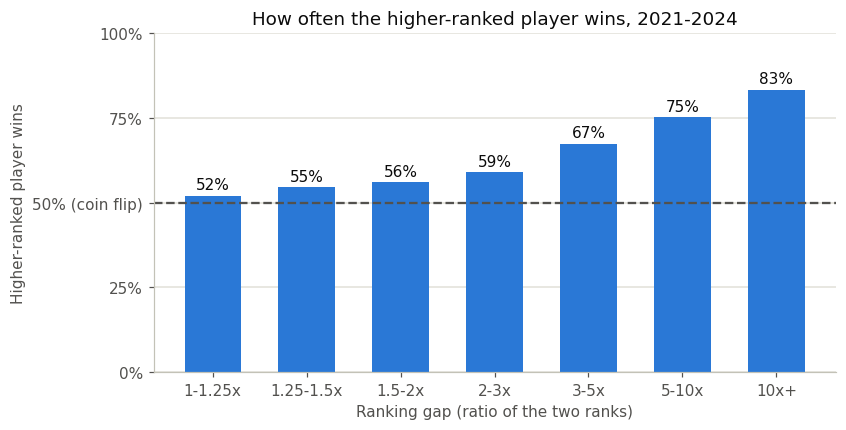

In [40]:
fig, ax = plt.subplots(figsize=(8, 4))
labels: list[str] = [f"{left:g}-{right:g}x" if np.isfinite(right) else f"{left:g}x+" for left, right in zip(RATIO_EDGES[:-1], RATIO_EDGES[1:])]
ax.bar(x=labels, height=by_ratio["favorite_win_rate"], color=BLUE, width=0.6)
ax.axhline(y=0.5, color=INK_SECONDARY, linewidth=1.5, linestyle="--")
for i, rate in enumerate(by_ratio["favorite_win_rate"]):
    ax.annotate(text=f"{rate:.0%}", xy=(i, rate), xytext=(0, 4), textcoords="offset points", ha="center", color=INK)
ax.set_ylim(bottom=0, top=1)
ax.set_yticks(ticks=[0, 0.25, 0.5, 0.75, 1], labels=["0%", "25%", "50% (coin flip)", "75%", "100%"])
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.set(title="How often the higher-ranked player wins, 2021-2024", xlabel="Ranking gap (ratio of the two ranks)", ylabel="Higher-ranked player wins")
plt.show()

排名差不到 1.5 倍時，勝率只比丟銅板高一點。要差 3 倍以上，排名高的人才明顯比較會贏。

再依比賽等級看。冷門比例是 1 減排名高的人的勝率。

In [41]:
by_level_rank: pd.DataFrame = ranked.groupby(by="tourney_level")["favorite_won"].agg(matches="count", favorite_win_rate="mean")
by_level_rank["upset_rate"] = 1 - by_level_rank["favorite_win_rate"]
by_level_rank.sort_values(by="upset_rate", ascending=False).round(decimals=3)

,matches,favorite_win_rate,upset_rate
tourney_level,,,
F,75,0.547,0.453
A,6284,0.616,0.384
M,2422,0.631,0.369
D,700,0.684,0.316
G,2026,0.705,0.295
O,61,0.738,0.262


- **年終總決賽（F）最常出冷門**，排名高的只贏 55%。F 包含 ATP 年終賽和 21 歲以下的新生代總決賽，參賽的都是當年排名相近的 8 人，排名差距本來就小。
- **大滿貫（G）和奧運（O）最少**，排名高的贏 70% 以上。大滿貫籤表 128 人，前幾輪常是前 10 名對 100 名以外，差距大。奧運只有 2024 巴黎一屆，64 場，參考就好。
- **一般比賽（A）比大師賽（M）多一點冷門**。A 級的參賽選手排名比較接近，差距小，冷門自然多。

最後列出大滿貫裡倍數最大的五場冷門。

In [42]:
upsets: pd.DataFrame = ranked[~ranked["favorite_won"]]
upsets[upsets["tourney_level"] == "G"].nlargest(n=5, columns="rank_ratio")[
    ["tourney_name", "round", "winner_name", "winner_rank", "loser_name", "loser_rank"]
]

,tourney_name,round,winner_name,winner_rank,loser_name,loser_rank
7011,Roland Garros,R128,Thiago Seyboth Wild,172.0,Daniil Medvedev,2.0
7332,Wimbledon,R64,Liam Broady,142.0,Casper Ruud,4.0
5874,Australian Open,R64,Mackenzie Mcdonald,65.0,Rafael Nadal,2.0
4852,Us Open,R128,Brandon Holt,303.0,Taylor Fritz,12.0
4940,Us Open,R16,Nick Kyrgios,25.0,Daniil Medvedev,1.0
